In [24]:
%load_ext autoreload
%autoreload 2
%matplotlib widget
%pwd

Task was destroyed but it is pending!
task: <Task pending name='Task-142' coro=<_async_in_context.<locals>.run_in_context() done, defined at /projectnb/batmanlab/mragoza/mambaforge/envs/warp/lib/python3.11/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-143' coro=<Kernel.shell_main() running at /projectnb/batmanlab/mragoza/mambaforge/envs/warp/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /projectnb/batmanlab/mragoza/mambaforge/envs/warp/lib/python3.11/site-packages/zmq/eventloop/zmqstream.py:563]>
/projectnb/batmanlab/mragoza/mambaforge/envs/warp/lib/python3.11/ast.py:50: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  return compile(source, filename, mode, flags,
Task was destroyed but it is pending!
task: <Task pending name='Task-143' coro=<Kernel.shell_main() running at /projectnb/batmanlab/mragoza/mambaforge/envs/warp/lib/python3.11/site-packages/ipyke

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


'/projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct'

In [25]:
import sys, os

def add_path(p: str):
    if p not in sys.path:
        sys.path.append(p)

add_path(os.environ['LP_ROOT'])
import project

add_path(os.environ['PROJECT'] + '/' + 'param_search')
import param_search as ps

ps.set_backend('sge')
ps.set_verbose(False)

# Gather examples

In [26]:
from pathlib import Path
data_root = Path(os.environ['PRIVATE']) / 'data' / 'BMC-4DCT'
data_root.exists()

True

In [27]:
manifest_path = data_root / 'metadata' / 'phase_manifest.csv'
manifest = project.fileio.load_csv(manifest_path)
manifest

Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/metadata/phase_manifest.csv


,case_id,subject_num,study_num,scan_role,resp_phase,image_path,series_description,case_phases,case_valid
0,4DCT_10_1,10,1,4DCT,0.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,0 0% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
1,4DCT_10_1,10,1,4DCT,10.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,10 10% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
2,4DCT_10_1,10,1,4DCT,20.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,20 20% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
3,4DCT_10_1,10,1,4DCT,30.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,30 30% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
4,4DCT_10_1,10,1,4DCT,40.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,40 40% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
...,...,...,...,...,...,...,...,...,...
484,unknown_53_1,53,1,unknown,50.0,converted/2026-07-16_batch/53/53_01_SBRT_4D_CT...,"Extended FOV, 50% Linear","(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
485,unknown_53_1,53,1,unknown,60.0,converted/2026-07-16_batch/53/53_01_SBRT_4D_CT...,"Extended FOV, 60% Linear","(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
486,unknown_53_1,53,1,unknown,70.0,converted/2026-07-16_batch/53/53_01_SBRT_4D_CT...,"Extended FOV, 70% Linear","(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
487,unknown_53_1,53,1,unknown,80.0,converted/2026-07-16_batch/53/53_01_SBRT_4D_CT...,"Extended FOV, 80% Linear","(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True


In [28]:
case_data = manifest[manifest.case_valid].sort_values(by=['subject_num', 'study_num'])
case_list = case_data.case_id.unique().tolist()
case_list

['4DCT_1_1',
 '4DCT_2_1',
 '4DCT_2_2',
 '4DCT_4_1',
 '4DCT_6_1',
 '4DCT_7_3',
 '4DCT_8_1',
 '4DCT_8_2',
 '4DCT_10_1',
 'unknown_12_1',
 'unknown_13_1',
 'unknown_14_1',
 'unknown_15_1',
 'unknown_16_1',
 'unknown_17_1',
 'unknown_17_3',
 'unknown_18_1',
 'unknown_19_1',
 'unknown_20_1',
 'unknown_22_1',
 'unknown_23_1',
 'unknown_26_1',
 'unknown_27_1',
 'unknown_28_1',
 'unknown_29_1',
 'unknown_30_1',
 'unknown_31_1',
 'unknown_32_1',
 'unknown_33_1',
 'unknown_34_1',
 'unknown_36_1',
 'unknown_37_1',
 'unknown_38_1',
 'unknown_39_1',
 'unknown_40_1',
 'unknown_40_5',
 'unknown_42_1',
 'unknown_42_4',
 'unknown_43_1',
 'unknown_44_1',
 'unknown_45_1',
 'unknown_47_1',
 'unknown_49_1',
 'unknown_50_1',
 'unknown_51_1',
 'unknown_52_1',
 'unknown_53_1']

In [29]:
config = project.fileio.load_config('2026-11-01_config.yaml')

config['dataset']['subjects'] = ['unknown_43_1']
config['dataset']['state_pairs'] = [(50, 0)]
config['dataset']['pipeline_tags']['image_registration'] = 'gil'
config['dataset']['pipeline_tags']['material_properties'] = 'const'
config['dataset']['pipeline_tags']['field_interpolation'] = 'int'

ex = project.get_examples(config['dataset'])[0]

mesh_path = ex.paths['target_mesh']
mesh = project.fileio.load_meshio(mesh_path)
(mesh.point_data['rho'] == 0).sum()

vox_path = ex.paths['material_dir'] / 'density.nii.gz'
vox = project.fileio.load_nibabel(vox_path).get_fdata()
vox.min()

Loading 2026-11-01_config.yaml
Gathering examples...
1 total
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_43_1/meshes/unknown_43_1_50_iso_v3d_gil_0_lung_rad_const_int.xdmf
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_43_1/fields/unknown_43_1_50_iso_v3d_const/density.nii.gz


np.float64(350.0)

# Setup experiment

In [30]:
base_dir = '2026-11-11_train' 

template = '''\
#!/bin/bash -l
#$ -N {job_name}
#$ -P batmanlab
#$ -pe omp 4
#$ -l gpus=1
#$ -l gpu_memory=32G
#$ -l h_rt=24:00:00
set -eo pipefail

mamba activate $PROJECT/mambaforge/envs/warp

export PYTHONPATH=$LP_ROOT:$PROJECT:$PYTHONPATH
export PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True"

python $LP_ROOT/scripts/train.py {config} \\
    --set dataset.variant={variant} \\
    --set dataset.subjects={subjects} \\
    --set dataset.state_pairs="[[50, {curr_phase}]]" \\
    --set dataset.pipeline_tags.image_registration={reg_tag} \\
    --set dataset.pipeline_tags.material_properties={mat_tag} \\
    --set dataset.pipeline_tags.field_interpolation=int \\
    --set training.split.method=metadata \\
    --set training.split.key=subject_num \\
    --set training.split.test_ratio=0.2 \\
    --set training.split.val_ratio=0.2 \\
    --set training.split.seed=11 \\
    --set training.model.backbone.out_channels=8 \\
    --set training.optimizer.lr=1e-4 \\
    --set training.pde_solver.material_type={material_type} \\
    --set training.pde_solver.tv_reg_weight={tv_reg_weight} \\
    --set training.pde_solver.cg_maxiter=10000 \\
    --set training.pde_solver.newton_atol=5e-5 \\
    --set training.seed={random_seed}

'''
name_format = 'job_{params_hash}'

grid = ps.param_grid(
    config='2026-11-01_config.yaml',
    variant='2026-11-01',
    subjects=','.join(case_list),
    curr_phase=[0,10,20,30,40,60,70,80,90],
    reg_tag='gil',
    mat_tag='const',
    material_type=['LE', 'NH'],
    tv_reg_weight=[1e-4],
    conv_channels=8,
    learning_rate=1e-4,
    random_seed=range(3)
)

len(grid)

54

In [31]:
base_dir = '2026-11-13_train' 

template = '''\
#!/bin/bash -l
#$ -N {job_name}
#$ -P batmanlab
#$ -pe omp 4
#$ -l gpus=1
#$ -l gpu_memory=32G
#$ -l h_rt=24:00:00
set -eo pipefail

mamba activate $PROJECT/mambaforge/envs/warp

export PYTHONPATH=$LP_ROOT:$PROJECT:$PYTHONPATH
export PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True"

python $LP_ROOT/scripts/train.py {config} \\
    --set dataset.variant={variant} \\
    --set dataset.subjects={subjects} \\
    --set dataset.state_pairs="[[50, {curr_phase}]]" \\
    --set dataset.pipeline_tags.image_registration={reg_tag} \\
    --set dataset.pipeline_tags.material_properties={mat_tag} \\
    --set dataset.pipeline_tags.field_interpolation=int \\
    --set training.split.method=metadata \\
    --set training.split.key=subject_num \\
    --set training.split.test_ratio=0.2 \\
    --set training.split.val_ratio=0.2 \\
    --set training.split.seed=11 \\
    --set training.model.backbone.out_channels=8 \\
    --set training.model.heads.E.v_max={E_max} \\
    --set training.model.heads.E.beta={E_beta} \\
    --set training.optimizer.lr=1e-4 \\
    --set training.pde_solver.material_type={material_type} \\
    --set training.pde_solver.tv_reg_weight=1e-4 \\
    --set training.pde_solver.cg_maxiter=10000 \\
    --set training.pde_solver.newton_atol=5e-5 \\
    --set training.seed={random_seed}

'''
name_format = 'job_{params_hash}'

grid = ps.param_grid(
    config='2026-11-01_config.yaml',
    variant='2026-11-01',
    subjects=','.join(case_list),
    curr_phase=[0],
    reg_tag='gil',
    mat_tag='const',
    E_max=[1e5, 2e4],
    E_beta=[None, 1.0],
    material_type=['LE', 'NH'],
    random_seed=range(3)
)

len(grid)

24

In [55]:
base_dir = '2026-11-15_train' 

# changelist:
# - set eps_err=1e-12 (prev: 1e-6)
# - clip gradient magnitude to 1.0

template = '''\
#!/bin/bash -l
#$ -N {job_name}
#$ -P batmanlab
#$ -pe omp 4
#$ -l gpus=1
#$ -l gpu_memory=32G
#$ -l h_rt=24:00:00
set -eo pipefail

mamba activate $PROJECT/mambaforge/envs/warp

export PYTHONPATH=$LP_ROOT:$PROJECT:$PYTHONPATH
export PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True"

python $LP_ROOT/scripts/train.py {config} \\
    --set dataset.variant={variant} \\
    --set dataset.subjects={subjects} \\
    --set dataset.state_pairs="[[50, {curr_phase}]]" \\
    --set dataset.pipeline_tags.image_registration={reg_tag} \\
    --set dataset.pipeline_tags.material_properties={mat_tag} \\
    --set dataset.pipeline_tags.field_interpolation=int \\
    --set training.split.method=metadata \\
    --set training.split.key=subject_num \\
    --set training.split.test_ratio=0.2 \\
    --set training.split.val_ratio=0.2 \\
    --set training.split.seed=11 \\
    --set training.model.backbone.out_channels=8 \\
    --set training.model.heads.E.v_max={E_max} \\
    --set training.model.heads.E.beta={E_beta} \\
    --set training.optimizer.lr=1e-4 \\
    --set training.pde_solver.material_type={material_type} \\
    --set training.pde_solver.tv_reg_weight=1e-4 \\
    --set training.pde_solver.eps_err=1e-12 \\
    --set training.pde_solver.cg_maxiter=10000 \\
    --set training.pde_solver.newton_atol=5e-5 \\
    --set training.seed={random_seed}

'''
name_format = 'job_{params_hash}'

grid = ps.param_grid(
    config='2026-11-01_config.yaml',
    variant='2026-11-01',
    subjects=','.join(case_list),
    curr_phase=[0,10,20,30,40,60,70,80,90],
    reg_tag='gil',
    mat_tag='const',
    E_max=[1e5],
    E_beta=[None],
    material_type=['LE', 'NH'],
    random_seed=range(3)
)

len(grid)

54

In [57]:
jobs = ps.setup(base_dir, template, name_format, grid, overwrite=True)
jobs

,job_name,job_state,n_submits,job_id,node_id,runtime,stdout,stderr,base_dir,work_dir,...,params.config,params.variant,params.subjects,params.curr_phase,params.reg_tag,params.mat_tag,params.E_max,params.E_beta,params.material_type,params.random_seed
0,job_20dcd12aa42a2ede,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,LE,0
1,job_ddb9b44bf5b5e8f1,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,LE,1
2,job_e528fc5ffdfa1af9,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,LE,2
3,job_f2dc704cb3abf6f6,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,NH,0
4,job_30a78961b8077611,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,NH,1
5,job_59bd9bf53e3c9616,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,NH,2
6,job_85207988298ba32c,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",10,gil,const,100000.0,None,LE,0
7,job_b5d3eca56b087c14,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",10,gil,const,100000.0,None,LE,1
8,job_78480c01b6512a6d,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",10,gil,const,100000.0,None,LE,2
9,job_80d76c8a42331d08,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",10,gil,const,100000.0,None,NH,0


In [58]:
jobs = ps.submit(jobs)

# Monitor submitted jobs

In [59]:
jobs = ps.load('2026-11-15_train')

In [ ]:
jobs = ps.recover(jobs)
jobs = ps.status(jobs)
jobs = ps.history(jobs)
jobs = ps.collect(jobs)
jobs.groupby('job_state').size()

In [42]:
import pandas as pd

def classify_output(stdout: str):
    if pd.isnull(stdout):
        return 'No stdout file'
    elif not str(stdout).strip():
        return 'No output message'
    elif 'Done' in stdout:
        return 'Complete'
    return 'Incomplete'

def classify_error(stderr: str):
    if pd.isnull(stderr):
        return 'No stderr file'    
    elif not str(stderr).strip():
        return 'No error message'
    elif 'Segmentation fault' in stderr:
        return 'Segmentation fault'
    elif 'CUDA out of memory' in stderr or 'Failed to allocate' in stderr:
        return 'CUDA out of memory'
    elif 'No CUDA GPUs are available' in stderr:
        return 'CUDA not available'
    elif 'Warp UserWarning' in stderr:
        return 'Warp user warning'
    elif 'Newton solver failed to converge' in stderr:
        return 'Failed to converge'
    elif 'Non-finite PDE residual' in stderr:
        return 'Non-finite PDE residual'
    elif 'WARNING: No metrics found' in stderr:
        return 'Load metrics warning'
    elif 'WARNING: No checkpoints found' in stderr:
        return 'Load checkpoint warning'
    return 'Uncategorized'

jobs['error_type'] = jobs.stderr.map(classify_error)
jobs['output_type'] = jobs.stdout.map(classify_output)

jobs.groupby(['params.material_type', 'params.E_max', 'output_type', 'error_type'], dropna=False)[['job_name']].count()

job_name
params.material_type params.E_max output_type error_type                  
LE                   20000.0      Complete    No error message           3
                                  Incomplete  Uncategorized              3
                     100000.0     Complete    No error message           3
                                  Incomplete  Uncategorized              3
NH                   20000.0      Complete    Failed to converge         3
                                  Incomplete  Uncategorized              3
                     100000.0     Complete    Failed to converge         3
                                  Incomplete  Uncategorized              3

In [41]:
query = jobs.error_type.eq('Uncategorized')
query_jobs = jobs[query]

job = query_jobs.iloc[0]
print(job)
print(job.stdout)
print(job.stderr)

job_name                                             job_20dcd12aa42a2ede
job_state                                                          FAILED
n_submits                                                               1
job_id                                                            8633336
node_id                                                           scc-307
runtime                                                          00:00:03
stdout                      └── 'seed':               0\nGathering exa...
stderr                    File "/projectnb/batmanlab/mragoza/lung-proj...
base_dir                /projectnb/batmanlab/mragoza/lung-project/note...
work_dir                /projectnb/batmanlab/mragoza/lung-project/note...
script_path             /projectnb/batmanlab/mragoza/lung-project/note...
output_path             /projectnb/batmanlab/mragoza/lung-project/note...
log_dir                 /projectnb/batmanlab/mragoza/lung-project/note...
stdout_path             /projectnb/bat

In [44]:
metrics = ps.outputs(
    jobs.reset_index(),
    meta_cols=['base_dir', 'job_name', 'job_id'],
    output_name='outputs/training/default/eval_metrics.csv',
    skip_errors=True
)

  0%|          | 0/24 [00:00<?, ?it/s]Job job_20dcd12aa42a2ede: file not found
Job job_ddb9b44bf5b5e8f1: file not found
Job job_e528fc5ffdfa1af9: file not found
Job job_f2dc704cb3abf6f6: file not found
Job job_30a78961b8077611: file not found
Job job_59bd9bf53e3c9616: file not found
 50%|█████     | 12/24 [00:00<00:00, 114.49it/s]Job job_18537979670a6131: file not found
Job job_7fa74fdc52128b16: file not found
Job job_5f8ab45e3414fd2a: file not found
Job job_3babee347fc4048c: file not found
Job job_3e0212461fa4aaa3: file not found
Job job_0d49c379612df46a: file not found
100%|██████████| 24/24 [00:00<00:00, 103.57it/s]


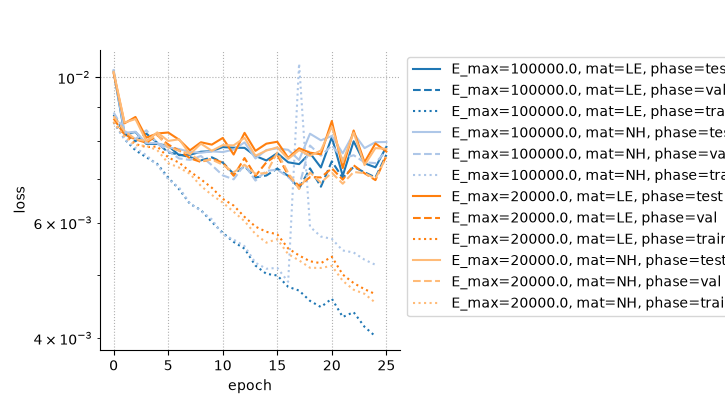

In [50]:
import project.visual.matplotlib as mpl_viz
import matplotlib.pyplot as plt

def training_plot(data, x, y, hue, style, agg='mean'):
    fig, axes = mpl_viz.subplot_grid(1, 1, 3, 3, padding=(1.0,3.25,0.5,0.5))
    colors = plt.get_cmap('tab20')
    styles = ['-', '--', ':']
    groupby_kws = dict(dropna=False, sort=False)
    for i, (hue_key, hue_data) in enumerate(data.groupby(hue, **groupby_kws)):
        for j, (style_key, style_data) in enumerate(hue_data.groupby(style, **groupby_kws)):
            points = style_data[[x, y]].dropna()
            if agg:
                points = points.groupby(x, as_index=False, sort=True)[y].agg(agg)
            else:
                points = points.sort_values(x)
            if points.empty:
                continue
            key_vals = dict(zip(hue, hue_key))
            key_vals[style] = style_key
            label = ', '.join(f'{k}={v}' for k, v in key_vals.items())
            axes[0,0].plot(
                points[x],
                points[y],
                color=colors(i % colors.N),
                linestyle=styles[j % len(styles)],
                label=label
            )
            axes[0,0].set_xlabel(x)
            axes[0,0].set_ylabel(y)
            axes[0,0].set_yscale('log')
            axes[0,0].grid(linestyle=':')
            axes[0,0].spines[['top', 'right']].set_visible(False)

    handles, labels = axes[0,0].get_legend_handles_labels()
    axes[0,0].legend(handles, labels, bbox_to_anchor=(1.0,1.0), loc='upper left')
    return fig, axes

metrics['mat'] = metrics['params.material_type']
metrics['E_max'] = metrics['params.E_max']

training_plot(metrics, x='epoch', y='loss', hue=['E_max', 'mat'], style='phase')
plt.pause(1.0)

In [ ]:
def load_trainer(curr_phase, material_type):
    import project.training
    best = best_lookup.loc[curr_phase, material_type]
    best = best.rename({'params.random_seed': 'seed'})
    train_job = train_jobs.loc[curr_phase, material_type, best.seed]
    output_dir = Path(train_job.work_dir) / 'outputs'
    config = get_config(curr_phase, material_type)
    examples = project.get_examples(config['dataset'])
    trainer = project.training.get_trainer(
        examples, config['training'], output_dir=output_dir
    )
    trainer.load_checkpoint(epoch=int(best.epoch))
    return trainer